# Probability Calibration

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
BASE = Path.cwd()
if not (BASE / "evidence").exists():
    BASE = BASE / "notebooks" 
assert (BASE / "evidence").is_dir(), "Open from the project root or notebooks."
EVIDENCE = BASE / "evidence"
def read_json(name):
    return json.loads((EVIDENCE / name).read_text(encoding="utf-8-sig"))
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})


## Question
Can recalibrating the existing main-model probabilities and choosing a validation threshold improve useful predictions? This experiment changes neither the forest's inputs nor its weights.

Five methods were declared: raw probabilities, sigmoid, logit, beta and isotonic calibration. Calibration fitting uses only earlier matured outcomes and excludes assessment property groups. Q3 selects the method and threshold; Q4 is reported afterwards. These historical periods were examined previously, so this is exploratory evidence, not a new untouched test.

In [2]:
result=read_json("probability_calibration_results.json")
display(pd.DataFrame([{"Role":"Calibration fit before July 2025","Services":result["calibration_training_services"]},
                      {"Role":"Q3 method/threshold validation","Services":result["validation_services"]},
                      {"Role":"Calibration refit before October 2025","Services":result["assessment_calibration_training_services"]},
                      {"Role":"Q4 historical assessment","Services":result["assessment_services"]}]))
display(pd.read_csv(EVIDENCE/"probability_calibration_validation.csv").round(4))

Role,Services
Calibration fit before July 2025,500
Q3 method/threshold validation,772
Calibration refit before October 2025,1334
Q4 historical assessment,410


method,services,positive_windows,TP,FP,FN,TN,threshold,accuracy,precision,recall,f1,brier,average_precision,roc_auc,always_no_accuracy
raw,772,71,44,142,27,559,0.45,0.7811,0.2366,0.6197,0.3424,0.1299,0.2523,0.7957,0.908
sigmoid,772,71,47,164,24,537,0.04,0.7565,0.2227,0.6620,0.3333,0.0850,0.2523,0.7957,0.908
logit,772,71,51,183,20,518,0.03,0.7370,0.2179,0.7183,0.3344,0.0848,0.2523,0.7957,0.908
beta,772,71,38,118,33,583,0.04,0.8044,0.2436,0.5352,0.3348,0.0848,0.2523,0.7957,0.908
isotonic,772,71,68,364,3,337,0.02,0.5246,0.1574,0.9577,0.2704,0.0864,0.1995,0.7490,0.908


## Historical assessment
The raw-score reference and calibration candidate use the same 410 service windows and 81 recorded positives. Both thresholds were chosen using Q3 rather than Q4. This is a different population and assessment from the original 100-service result; the percentages must not be mixed.

Configuration,services,positive_windows,accuracy,precision,recall,brier,TP,FP,FN,TN
Raw scores; validation threshold,410,81,0.6707,0.3151,0.5679,0.1959,46,100,35,229
logit calibration; validation threshold,410,81,0.4976,0.2659,0.8765,0.1623,71,196,10,133


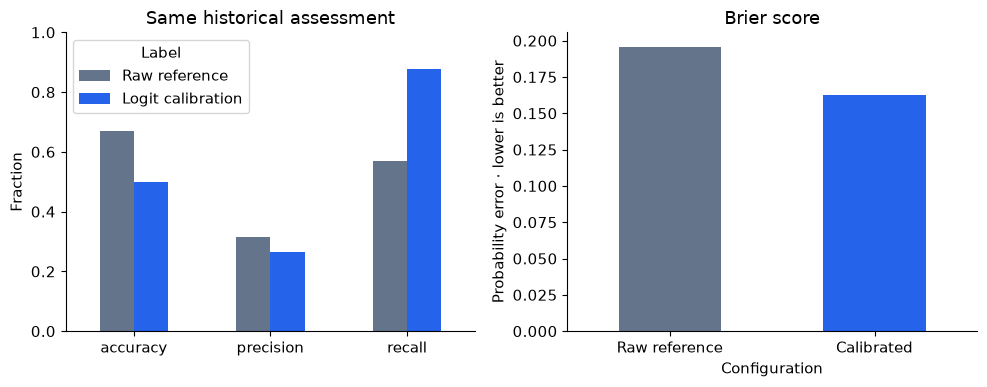

Passed the declared exploratory gate: False
Deployed: False


In [3]:
comparison=pd.read_csv(EVIDENCE/"probability_calibration_assessment.csv")
display(comparison[["Configuration","services","positive_windows","accuracy","precision","recall","brier","TP","FP","FN","TN"]].round(4))
fig,axes=plt.subplots(1,2,figsize=(10,4))
comparison["Label"]=["Raw reference","Logit calibration"]
comparison.set_index("Label")[["accuracy","precision","recall"]].T.plot.bar(ax=axes[0],color=["#64748b","#2563eb"],rot=0)
axes[0].set_ylim(0,1);axes[0].set_ylabel("Fraction");axes[0].set_title("Same historical assessment")
comparison.set_index("Configuration")["brier"].plot.bar(ax=axes[1],color=["#64748b","#2563eb"],rot=0)
axes[1].set_ylabel("Probability error · lower is better");axes[1].set_title("Brier score")
axes[1].set_xticklabels(["Raw reference","Calibrated"])
plt.tight_layout();plt.show()
print("Passed the declared exploratory gate:",result["passed_exploratory_gate"])
print("Deployed:",result["deployed"])

## Decision
Logit calibration reduced probability error, but its validation-selected threshold generated more false alerts and lower assessment precision and accuracy. It did not pass the declared gate and was not deployed. Better probability calibration alone does not establish a better yes/no decision rule.

Implementation: `scripts/test_return_probability_calibration.py`. Original protocol, source hash and numerical results: `outputs/model_validation/20261028_probability_calibration`. Frozen model weights and the future collection protocol remain unchanged.